# 04 - Tree-Based Models
RandomForestRegressor and GradientBoostingRegressor, tuned with a time-ordered cross-validation (TimeSeriesSplit) on the training data only. The test set (2024+) is used once, for the final comparison.

Features match the linear-model notebook: item, year, month.

In [1]:
import sys
sys.path.append('..')
import pandas as pd
from src.preprocessing import clean_data, time_split
from src.evaluation import evaluate_regression

df = clean_data(pd.read_csv('../data/us_average_prices_monthly.csv'))
train, test = time_split(df, '2024-01-01')   # older rows = train, 2024+ = test

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Column names produced by clean_data. CHECK these against df.columns and edit if they differ.
DATE, ITEM, CAT, PRICE = 'date', 'item', 'category', 'price'

missing = [c for c in (DATE, ITEM, CAT, PRICE) if c not in df.columns]
assert not missing, f"Rename the constants above to match df.columns: {list(df.columns)} (missing: {missing})"
print(df.shape, df[DATE].min().date(), "to", df[DATE].max().date())

(8869, 8) 2015-01-01 to 2026-07-01


## 1. Prepare features
Sort by date first so that `TimeSeriesSplit` always validates on later rows than it trains on.

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_squared_error

def add_features(d):
    d = d.sort_values(DATE, kind='stable').reset_index(drop=True)
    d[ITEM] = d[ITEM].astype(str)
    d['year'] = d[DATE].dt.year
    d['month'] = d[DATE].dt.month
    return d

train, test = add_features(train), add_features(test)
FEATURES = [ITEM, 'year', 'month']
X_train, y_train = train[FEATURES], train[PRICE]
X_test,  y_test  = test[FEATURES],  test[PRICE]
print(len(train), len(test))

6971 1898


## 2. Pipeline and time-ordered tuning
The one-hot encoder lives inside the pipeline, so in every CV fold it is fitted on that fold's training rows only. Trees do not need scaling.

In [4]:
preprocess = ColumnTransformer(
    [('item', OneHotEncoder(handle_unknown='ignore', sparse_output=False), [ITEM])],
    remainder='passthrough')          # year and month pass through unchanged

tscv = TimeSeriesSplit(n_splits=5)    # each fold trains on the past and validates on the next block

def tune(model, grid):
    pipe = Pipeline([('prep', preprocess), ('model', model)])
    search = GridSearchCV(pipe, {f'model__{k}': v for k, v in grid.items()},
                          cv=tscv, scoring='neg_root_mean_squared_error', n_jobs=-1)
    return search.fit(X_train, y_train)

searches = {
    'Random Forest': tune(
        RandomForestRegressor(random_state=42),
        {'n_estimators': [100, 300], 'max_depth': [10, 20, None], 'min_samples_leaf': [1, 5]}),
    'Gradient Boosting': tune(
        GradientBoostingRegressor(random_state=42),
        {'n_estimators': [100, 300], 'learning_rate': [0.05, 0.1], 'max_depth': [3, 5]}),
}

for name, s in searches.items():
    print(f"{name}: best CV RMSE = {-s.best_score_:.4f}  params = {s.best_params_}")

Random Forest: best CV RMSE = 0.4116  params = {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 100}
Gradient Boosting: best CV RMSE = 0.4344  params = {'model__learning_rate': 0.1, 'model__max_depth': 5, 'model__n_estimators': 300}


## 3. Test-set evaluation
Same `evaluate_regression` as the linear models, so the numbers are comparable.

In [5]:
preds, results = {}, {}
for name, s in searches.items():
    preds[name] = s.predict(X_test)
    results[name] = evaluate_regression(y_test, preds[name])
    print(name, results[name])

# Put these three numbers per model in the PR description and in Table 1
display(pd.DataFrame(results).T)

best_name = min(preds, key=lambda n: np.sqrt(mean_squared_error(y_test, preds[n])))
print("Lowest test RMSE among tree models:", best_name)

Random Forest {'RMSE': np.float64(0.7878067323111787), 'MAE': 0.43948787144362556, 'R2': 0.9317329766194716}
Gradient Boosting {'RMSE': np.float64(0.840292779972293), 'MAE': 0.5044898928008583, 'R2': 0.9223336572140254}


,RMSE,MAE,R2
Random Forest,0.787807,0.439488,0.931733
Gradient Boosting,0.840293,0.504490,0.922334


Lowest test RMSE among tree models: Random Forest


## 4. Feature importance

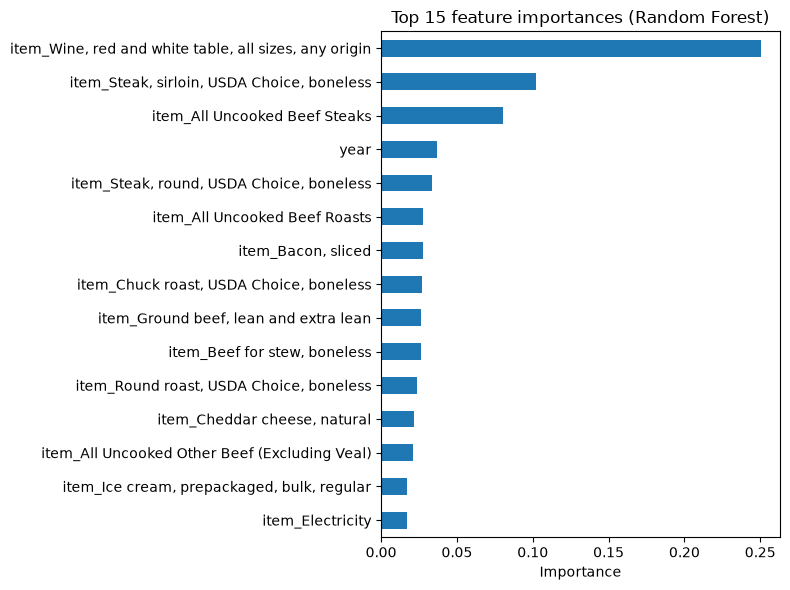

year: 0.037  month: 0.005  all item columns combined: 0.958


In [6]:
import os
os.makedirs('figures', exist_ok=True)

best_pipe = searches[best_name].best_estimator_
names = best_pipe.named_steps['prep'].get_feature_names_out()
names = [n.replace('item__', '').replace('remainder__', '') for n in names]
imp = pd.Series(best_pipe.named_steps['model'].feature_importances_, index=names).sort_values()

imp.tail(15).plot.barh(figsize=(8, 6), title=f'Top 15 feature importances ({best_name})')
plt.xlabel('Importance'); plt.tight_layout()
plt.savefig('figures/feature_importance.png', dpi=200); plt.show()

# Year and month are single columns; show them next to the item total
print("year:", round(imp['year'], 3), " month:", round(imp['month'], 3),
      " all item columns combined:", round(imp.drop(['year', 'month']).sum(), 3))

## 5. Predicted vs. actual (test period)

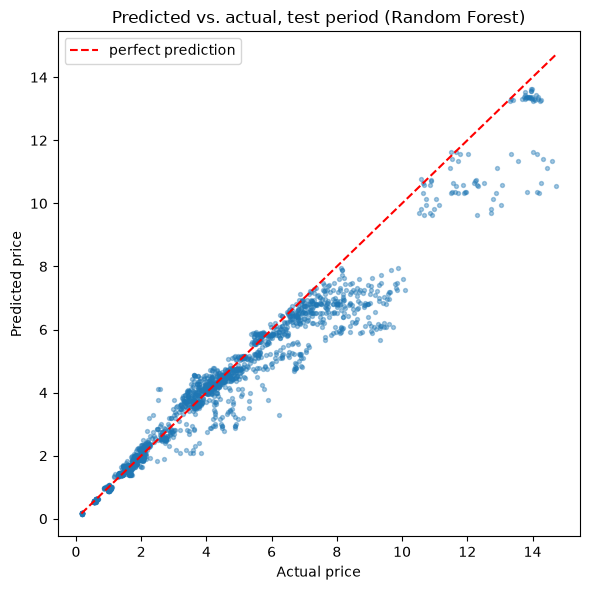

In [7]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, preds[best_name], s=8, alpha=0.4)
lims = [min(y_test.min(), preds[best_name].min()), max(y_test.max(), preds[best_name].max())]
plt.plot(lims, lims, 'r--', label='perfect prediction')
plt.xlabel('Actual price'); plt.ylabel('Predicted price'); plt.legend()
plt.title(f'Predicted vs. actual, test period ({best_name})'); plt.tight_layout()
plt.savefig('figures/predicted_vs_actual.png', dpi=200); plt.show()

## 6. Limitation check: can trees predict prices above anything they saw in training?
Tree models predict averages of training prices, so they cannot go above the highest price seen for an item in the training period.

In [8]:
train_max = train.groupby(ITEM)[PRICE].max()
above = (y_test > test[ITEM].map(train_max)).mean()
print(f"{above:.1%} of test rows are above that item's highest training price")

36.5% of test rows are above that item's highest training price


## 7. Summary

**Validation:** Data were sorted by date and tuned with `TimeSeriesSplit(n_splits=5)` on the training data (6,971 rows, through December 2023), using grid search on CV RMSE. The test set (1,898 rows, 2024+) was used once, for the final comparison.

**Best parameters:**
- Random Forest: n_estimators=100, max_depth=None, min_samples_leaf=1 (CV RMSE 0.4116)
- Gradient Boosting: n_estimators=300, learning_rate=0.1, max_depth=5 (CV RMSE 0.4344)

**Test results:**

| Model | RMSE | MAE | R² |
|---|---|---|---|
| Random Forest | 0.7878 | 0.4395 | 0.9317 |
| Gradient Boosting | 0.8403 | 0.5045 | 0.9223 |
| Linear baseline (from 03) | 0.9590 | 0.6582 | 0.8988 |

**Takeaway:** Random Forest had the lowest test error, with an RMSE about 18% lower and an MAE about 33% lower than the linear baseline. Both tree models beat the linear models, which suggests the relationship between item, date and price is not purely linear. Test error is higher than CV error (0.79 vs. 0.41), as expected because the test period contains prices above what the models saw in training.

**Feature importance:** The item explains almost all the importance (about 96% combined), year about 4% and month under 1%. Price level is driven mainly by which item it is, with a small contribution from the long-term trend and almost none from seasonality, which matches the EDA.

**Limitation:** Trees cannot predict above the highest price seen for an item in training, and 36.5% of test rows exceed that level, so predictions are likely to understate prices when they keep rising. Gradient Boosting's best parameters sit at the edge of the grid (the highest values tried), so a wider search might improve it.